# 01 · Database pipeline (SQLite) — create, read, update, delete

**Project:** Air Quality Prediction (IDC409, topic 11) · **Dataset:** `city_day.csv` (26 Indian cities, 2015-01-01 → 2020-07-01)

**Requirement covered:** *"Database to be used: read, write and modify"* and the deliverable *"SQLite database or CSV pipeline"*.

What this notebook does
1. Inspect the raw CSV with **pandas / numpy** (requirement 1).
2. **CREATE** a database schema (`sql/schema.sql`): raw layer → dimension (`dim_city`) → fact (`fact_aqi`) + `audit_log`, `festival_calendar`, `model_results`.
3. **INSERT** the CSV into the raw layer.
4. Run the cleaning pipeline as SQL (`sql/clean_pipeline.sql`) – every step is an **UPDATE / DELETE / INSERT…SELECT** and is recorded in `audit_log`.
5. **READ** with 14 analytical queries (`sql/queries.sql`): joins, aggregates, window functions, CASE.
6. A hand-written **INSERT → UPDATE → DELETE** demo and a **ROLLBACK** demo.
7. Integrity checks.

```
raw_city_day ──(clean, INSERT…SELECT)──► fact_aqi ◄── dim_city (city_id, name, state, region)
                                            │
        festival_calendar   audit_log   model_results   aqi_features (written by notebook 02)
```

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import db, config
from src.config import DATA_RAW, DB_PATH, SQL_DIR
from src.viz import set_style, save_fig
set_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("project root folder:", ROOT.name)

project root folder: aqi-prediction


## 1 · First look at the raw CSV (pandas + numpy)

In [2]:
raw = pd.read_csv(DATA_RAW)
print("shape:", raw.shape)
raw.info()
display(raw.head())

shape: (29531, 16)
<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
# numpy: share of missing values per column, computed on the underlying array
num = raw.select_dtypes("number")
miss = np.isnan(num.to_numpy()).mean(axis=0) * 100
display(pd.Series(miss, index=num.columns).round(1).sort_values(ascending=False).to_frame("% missing"))
print("cities:", raw["City"].nunique(), "| date range:", raw["Date"].min(), "->", raw["Date"].max())

,% missing
Xylene,61.3
PM10,37.7
NH3,35.0
Toluene,27.2
Benzene,19.0
AQI,15.9
PM2.5,15.6
NOx,14.2
O3,13.6
SO2,13.1


cities: 26 | date range: 2015-01-01 -> 2020-07-01


## 2 · CREATE – schema

`sql/schema.sql` drops and re-creates all objects, so this notebook can be re-run safely.
Column `NO` is renamed `no_` because `NO` is an SQL keyword (mapping lives in `src/config.py`).

In [4]:
if DB_PATH.exists():
    DB_PATH.unlink()                      # start from an empty database file
conn = db.get_conn()
db.run_script(conn, SQL_DIR / "schema.sql")
print(open(SQL_DIR / "schema.sql").read()[:1800], "\n...")

-- =====================================================================================
-- AQI project - database schema (SQLite)
-- Star-like design:  dim_city  <-  fact_aqi  (+ festival_calendar, audit_log, model_results)
-- =====================================================================================
PRAGMA foreign_keys = ON;

DROP VIEW  IF EXISTS v_aqi_full;
DROP VIEW  IF EXISTS v_city_summary;
DROP TABLE IF EXISTS model_results;
DROP TABLE IF EXISTS audit_log;
DROP TABLE IF EXISTS festival_calendar;
DROP TABLE IF EXISTS aqi_features;
DROP TABLE IF EXISTS fact_aqi;
DROP TABLE IF EXISTS dim_city;
DROP TABLE IF EXISTS raw_city_day;

-- 1) RAW layer: exactly what the CSV contained (only column names normalised)
CREATE TABLE raw_city_day (
    city TEXT, date TEXT,
    pm25 REAL, pm10 REAL, no_ REAL, no2 REAL, nox REAL, nh3 REAL, co REAL, so2 REAL,
    o3 REAL, benzene REAL, toluene REAL, xylene REAL, aqi REAL, aqi_bucket TEXT
);

-- 2) DIMENSION: one row per city
CREATE TABLE

In [5]:
db.query("SELECT type, name FROM sqlite_master WHERE name NOT LIKE 'sqlite_%' ORDER BY type DESC, name", conn)

,type,name
0,view,v_aqi_full
1,view,v_city_summary
2,table,audit_log
3,table,dim_city
4,table,fact_aqi
5,table,festival_calendar
6,table,model_results
7,table,raw_city_day
8,index,idx_fact_date


## 3 · INSERT – load the raw CSV into `raw_city_day`

In [6]:
n = db.load_raw_csv(conn, DATA_RAW)
print(f"{n:,} rows inserted into raw_city_day")
db.query("SELECT * FROM raw_city_day LIMIT 5", conn)

29,531 rows inserted into raw_city_day


,city,date,pm25,pm10,no_,no2,nox,nh3,co,so2,o3,benzene,toluene,xylene,aqi,aqi_bucket
0,Ahmedabad,2015-01-01,None,None,0.92,18.22,17.15,None,0.92,27.64,133.36,0.00,0.02,0.00,None,None
1,Ahmedabad,2015-01-02,None,None,0.97,15.69,16.46,None,0.97,24.55,34.06,3.68,5.50,3.77,None,None
2,Ahmedabad,2015-01-03,None,None,17.40,19.30,29.70,None,17.40,29.07,30.70,6.80,16.40,2.25,None,None
3,Ahmedabad,2015-01-04,None,None,1.70,18.48,17.97,None,1.70,18.59,36.08,4.43,10.14,1.00,None,None
4,Ahmedabad,2015-01-05,None,None,22.10,21.42,37.76,None,22.10,39.33,39.31,7.01,18.89,2.78,None,None


## 4 · UPDATE / DELETE / INSERT…SELECT – cleaning pipeline in SQL

Each step below is a named block in `sql/clean_pipeline.sql`. Before each destructive step we look at the evidence.

**Evidence 1 – are there duplicates or inconsistent city names?**

In [7]:
display(db.query("SELECT COUNT(*) AS rows_total, COUNT(DISTINCT city || date) AS distinct_city_date FROM raw_city_day", conn))
display(db.query("SELECT city, COUNT(*) AS n FROM raw_city_day GROUP BY city ORDER BY city", conn).T)

,rows_total,distinct_city_date
0,29531,29531


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
city,Ahmedabad,Aizawl,Amaravati,Amritsar,Bengaluru,Bhopal,Brajrajnagar,Chandigarh,Chennai,Coimbatore,Delhi,Ernakulam,Gurugram,Guwahati,Hyderabad,Jaipur,Jorapokhar,Kochi,Kolkata,Lucknow,Mumbai,Patna,Shillong,Talcher,Thiruvananthapuram,Visakhapatnam
n,2009,113,951,1221,2009,289,938,304,2009,386,2009,162,1679,502,2006,1114,1169,162,814,2009,2009,1858,310,925,1112,1462


**Evidence 2 – rows that contain no information at all** (all 12 pollutants *and* AQI missing).

In [8]:
db.query('''SELECT COUNT(*) AS completely_empty_rows FROM raw_city_day
            WHERE pm25 IS NULL AND pm10 IS NULL AND no_ IS NULL AND no2 IS NULL AND nox IS NULL AND nh3 IS NULL
              AND co IS NULL AND so2 IS NULL AND o3 IS NULL AND benzene IS NULL AND toluene IS NULL
              AND xylene IS NULL AND aqi IS NULL''', conn)

,completely_empty_rows
0,1374


Now run the **first block** of steps (name clean-up, duplicates, empty rows, dimension table).

In [9]:
steps = db.load_named_sql(SQL_DIR / "clean_pipeline.sql")
print("steps defined:", list(steps))
first = ["trim_city_names", "unify_city_aliases", "delete_duplicate_rows", "delete_empty_rows", "load_dim_city"]
log1 = db.run_steps(conn, steps, only=first)

steps defined: ['trim_city_names', 'unify_city_aliases', 'delete_duplicate_rows', 'delete_empty_rows', 'load_dim_city', 'load_fact_aqi', 'zeros_to_null', 'fix_aqi_bucket', 'flag_outliers', 'flag_suspect_cities']
[trim_city_names       ]       0 rows  - UPDATE - strip stray whitespace from city names
[unify_city_aliases    ]       0 rows  - UPDATE - map historical / alternative spellings to the canonical city name
[delete_duplicate_rows ]       0 rows  - DELETE - keep only the first row for every (city, date) pair
[delete_empty_rows     ]   1,374 rows  - DELETE - rows where all 12 pollutants AND the AQI are missing carry no information
[load_dim_city         ]      26 rows  - INSERT - one dimension row per distinct city


**UPDATE with parameters** – enrich the dimension with state and region, and **INSERT** the festival lookup table.

In [10]:
print(db.populate_city_metadata(conn), "dim_city rows updated;", db.populate_festivals(conn), "festival dates inserted")
db.query("SELECT * FROM dim_city ORDER BY region, city_name", conn)

26 dim_city rows updated; 18 festival dates inserted


,city_id,city_name,state,region
0,6,Bhopal,Madhya Pradesh,Central
1,7,Brajrajnagar,Odisha,East
2,17,Jorapokhar,Jharkhand,East
3,19,Kolkata,West Bengal,East
4,22,Patna,Bihar,East
5,24,Talcher,Odisha,East
6,4,Amritsar,Punjab,North
7,8,Chandigarh,Chandigarh (UT),North
8,11,Delhi,Delhi (UT),North
9,13,Gurugram,Haryana,North


**Evidence 3 – zero readings.** Are zeros genuine measurements or placeholders? Mumbai has almost identical zero counts in
CO/Benzene/Toluene/Xylene – a typical signature of 'no reading' written as 0.

In [11]:
db.query('''SELECT r.city,
       SUM(co = 0) AS co_zero, SUM(nox = 0) AS nox_zero, SUM(benzene = 0) AS benzene_zero,
       SUM(toluene = 0) AS toluene_zero, SUM(xylene = 0) AS xylene_zero,
       SUM(pm25 = 0) AS pm25_zero, SUM(so2 = 0) AS so2_zero
FROM raw_city_day r GROUP BY r.city
HAVING co_zero + nox_zero + benzene_zero + toluene_zero + xylene_zero > 0
ORDER BY benzene_zero DESC LIMIT 8''', conn)

,city,co_zero,nox_zero,benzene_zero,toluene_zero,xylene_zero,pm25_zero,so2_zero
0,Mumbai,1095,1,1006,1007,1006,0,0
1,Gurugram,32,23,269,253,0,0,0
2,Ahmedabad,0,7,257,246,224,0,0
3,Visakhapatnam,187,191,198,198,199,0,0
4,Patna,47,1,70,55,68,0,0
5,Amaravati,17,0,67,18,0,0,0
6,Hyderabad,70,21,38,18,33,0,0
7,Delhi,87,2,8,108,148,0,0


PM2.5 and SO2 are never exactly 0 while the five other columns are zero thousands of times → we treat zeros in **CO, NOx, Benzene, Toluene, Xylene as missing**.
(Trade-off: a few may be true 'below detection limit' values; Benzene/Toluene/Xylene end up being dropped or weak features anyway – see notebook 04.)

Run the **second block**: build the fact table, replace placeholder zeros, fix inconsistent categories, flag outliers and suspect cities.

In [12]:
rest = [s for s in steps if s not in first]
log2 = db.run_steps(conn, steps, only=rest)

[load_fact_aqi         ]  28,157 rows  - INSERT ... SELECT - move cleaned raw rows into the fact table with the city surrogate key
[zeros_to_null         ]   5,913 rows  - UPDATE - exact zeros in CO, NOx, Benzene, Toluene, Xylene are placeholders for "no reading" (see EDA), set to NULL
[fix_aqi_bucket        ]       0 rows  - UPDATE - make aqi_bucket consistent with the CPCB bands of the numeric AQI
[flag_outliers         ]     547 rows  - UPDATE - flag readings above the 0-500 AQI scale or at sensor ceilings (kept, not deleted)
[flag_suspect_cities   ]   1,559 rows  - UPDATE - flag cities where NO equals CO on >30% of days (copy-paste data-entry error signature)


**Why is a city flagged as suspect?** The rule `NO == CO on > 30 % of days` caught exactly one city. Evidence:

In [13]:
display(db.query(db.load_named_sql(SQL_DIR / "queries.sql")["q13_data_quality_no_equals_co"]["sql"], conn))
db.query('''SELECT city, ROUND(AVG(aqi),0) AS mean_aqi, ROUND(MAX(aqi),0) AS max_aqi, SUM(aqi>500) AS days_above_500
            FROM v_aqi_full GROUP BY city ORDER BY mean_aqi DESC LIMIT 5''', conn)

,city,pct_days_no_equals_co,outlier_rows
0,Ahmedabad,84.5,412
1,Thiruvananthapuram,0.4,0
2,Coimbatore,0.3,0
3,Aizawl,0.0,0
4,Amaravati,0.0,0
5,Amritsar,0.0,4


,city,mean_aqi,max_aqi,days_above_500
0,Ahmedabad,452.0,2049.0,412
1,Delhi,259.0,716.0,48
2,Patna,241.0,619.0,25
3,Gurugram,225.0,891.0,22
4,Lucknow,218.0,707.0,15


Ahmedabad: the NO and CO columns are identical on most days (copy-paste error) and it alone produces 75 % of all AQI values above the 500 scale limit.
It is **kept in the database but flagged `is_suspect = 1`**; modelling excludes it and notebook 05 re-runs with it as a sensitivity test.

## 5 · The pipeline's own change history (`audit_log`)

In [14]:
audit = db.query("SELECT * FROM audit_log ORDER BY log_id", conn)
audit.to_csv(config.RESULTS_DIR / "db_audit_log.csv", index=False)
audit

,log_id,ts,step,table_name,rows_affected,description
0,1,2026-10-29 05:23:35,trim_city_names,raw_city_day,0,UPDATE - strip stray whitespace from city names
1,2,2026-10-29 05:23:35,unify_city_aliases,raw_city_day,0,UPDATE - map historical / alternative spelling...
2,3,2026-10-29 05:23:35,delete_duplicate_rows,raw_city_day,0,DELETE - keep only the first row for every (ci...
3,4,2026-10-29 05:23:35,delete_empty_rows,raw_city_day,1374,DELETE - rows where all 12 pollutants AND the ...
4,5,2026-10-29 05:23:35,load_dim_city,dim_city,26,INSERT - one dimension row per distinct city
5,6,2026-10-29 05:23:36,load_fact_aqi,fact_aqi,28157,INSERT ... SELECT - move cleaned raw rows into...
6,7,2026-10-29 05:23:36,zeros_to_null,fact_aqi,5913,"UPDATE - exact zeros in CO, NOx, Benzene, Tolu..."
7,8,2026-10-29 05:23:36,fix_aqi_bucket,fact_aqi,0,UPDATE - make aqi_bucket consistent with the C...
8,9,2026-10-29 05:23:36,flag_outliers,fact_aqi,547,UPDATE - flag readings above the 0-500 AQI sca...
9,10,2026-10-29 05:23:36,flag_suspect_cities,fact_aqi,1559,UPDATE - flag cities where NO equals CO on >30...


## 6 · READ – 14 analytical queries

All queries live in `sql/queries.sql` (open it – it is a good place to show your SQL skills). Joins, `GROUP BY`, `HAVING`, `CASE`, window functions (`AVG() OVER`), date functions (`strftime`, `julianday`) and views are all used.

In [15]:
queries = db.load_named_sql(SQL_DIR / "queries.sql")
def show(name):
    q = queries[name]
    print("-" * 100); print(f"{name}: {q['desc']}"); print(q["sql"])
    display(db.query(q["sql"], conn))
for name in ["q01_table_row_counts", "q02_city_coverage"]:
    show(name)

----------------------------------------------------------------------------------------------------
q01_table_row_counts: sanity check of every layer
SELECT 'raw_city_day' AS tbl, COUNT(*) AS n FROM raw_city_day
UNION ALL SELECT 'dim_city', COUNT(*) FROM dim_city
UNION ALL SELECT 'fact_aqi', COUNT(*) FROM fact_aqi
UNION ALL SELECT 'festival_calendar', COUNT(*) FROM festival_calendar
UNION ALL SELECT 'audit_log', COUNT(*) FROM audit_log;


,tbl,n
0,raw_city_day,28157
1,dim_city,26
2,fact_aqi,28157
3,festival_calendar,18
4,audit_log,10


----------------------------------------------------------------------------------------------------
q02_city_coverage: how many days / AQI values does each city have, and over which period?
SELECT city, region, n_days, n_days_with_aqi, first_date, last_date,
       ROUND(100.0 * (n_days - n_days_with_aqi) / n_days, 1) AS pct_aqi_missing, mean_aqi, is_suspect
FROM v_city_summary ORDER BY n_days DESC;


,city,region,n_days,n_days_with_aqi,first_date,last_date,pct_aqi_missing,mean_aqi,is_suspect
0,Delhi,North,2009,1999,2015-01-01,2020-07-01,0.5,259.5,0
1,Bengaluru,South,2008,1910,2015-01-01,2020-07-01,4.9,94.3,0
2,Hyderabad,South,2003,1880,2015-01-04,2020-07-01,6.1,109.2,0
3,Lucknow,North,1991,1893,2015-01-01,2020-07-01,4.9,218.0,0
4,Chennai,South,1989,1884,2015-01-01,2020-07-01,5.3,114.5,0
5,Mumbai,West,1989,775,2015-01-01,2020-07-01,61.0,105.4,0
6,Patna,East,1709,1459,2015-06-01,2020-07-01,14.6,240.8,0
7,Gurugram,North,1622,1453,2015-11-27,2020-07-01,10.4,225.1,0
8,Ahmedabad,West,1559,1334,2015-01-01,2020-07-01,14.4,452.1,1
9,Visakhapatnam,South,1429,1171,2016-07-01,2020-07-01,18.1,117.3,0


In [16]:
for name in ["q03_missing_by_column", "q04_worst_days_delhi", "q05_monthly_mean_core_cities"]:
    show(name)

----------------------------------------------------------------------------------------------------
q03_missing_by_column: percentage of NULLs per column in the fact table
SELECT ROUND(100.0*SUM(pm25 IS NULL)/COUNT(*),1) AS pm25, ROUND(100.0*SUM(pm10 IS NULL)/COUNT(*),1) AS pm10,
       ROUND(100.0*SUM(no2 IS NULL)/COUNT(*),1) AS no2, ROUND(100.0*SUM(so2 IS NULL)/COUNT(*),1) AS so2,
       ROUND(100.0*SUM(co IS NULL)/COUNT(*),1) AS co, ROUND(100.0*SUM(o3 IS NULL)/COUNT(*),1) AS o3,
       ROUND(100.0*SUM(nh3 IS NULL)/COUNT(*),1) AS nh3, ROUND(100.0*SUM(benzene IS NULL)/COUNT(*),1) AS benzene,
       ROUND(100.0*SUM(xylene IS NULL)/COUNT(*),1) AS xylene, ROUND(100.0*SUM(aqi IS NULL)/COUNT(*),1) AS aqi
FROM fact_aqi;


,pm25,pm10,no2,so2,co,o3,nh3,benzene,xylene,aqi
0,11.5,34.7,7.9,8.8,10.7,9.4,31.8,28.6,65.6,11.7


----------------------------------------------------------------------------------------------------
q04_worst_days_delhi: the 10 most polluted days recorded in Delhi
SELECT date, aqi, aqi_bucket, pm25, pm10 FROM v_aqi_full
WHERE city = 'Delhi' AND aqi IS NOT NULL ORDER BY aqi DESC LIMIT 10;


,date,aqi,aqi_bucket,pm25,pm10
0,2016-11-07,716.0,Severe,488.57,527.64
1,2017-11-09,677.0,Severe,495.90,652.21
2,2016-11-06,676.0,Severe,685.36,708.80
3,2017-11-08,675.0,Severe,639.19,796.88
4,2019-11-03,659.0,Severe,582.28,706.58
5,2016-11-03,625.0,Severe,482.40,483.99
6,2017-11-12,613.0,Severe,465.08,622.40
7,2016-01-08,603.0,Severe,339.87,540.86
8,2016-11-05,603.0,Severe,588.39,763.58
9,2017-11-10,597.0,Severe,370.73,496.48


----------------------------------------------------------------------------------------------------
q05_monthly_mean_core_cities: month-of-year profile (all years pooled) for Delhi, Chandigarh and Mumbai
SELECT city, CAST(strftime('%m', date) AS INTEGER) AS month, ROUND(AVG(aqi), 1) AS mean_aqi, COUNT(aqi) AS n
FROM v_aqi_full WHERE city IN ('Delhi','Chandigarh','Mumbai')
GROUP BY city, month ORDER BY city, month;


,city,month,mean_aqi,n
0,Chandigarh,1,94.1,31
1,Chandigarh,2,93.4,29
2,Chandigarh,3,55.4,31
3,Chandigarh,4,44.6,29
4,Chandigarh,5,74.1,31
5,Chandigarh,6,66.5,30
6,Chandigarh,7,66.0,1
7,Chandigarh,9,85.2,25
8,Chandigarh,10,140.2,31
9,Chandigarh,11,168.5,30


In [17]:
for name in ["q06_severe_days_per_city_year", "q07_rolling_7day_delhi"]:
    show(name)

----------------------------------------------------------------------------------------------------
q06_severe_days_per_city_year: number of 'Severe' days per city and year (top rows)
SELECT city, strftime('%Y', date) AS year, SUM(aqi_bucket = 'Severe') AS severe_days, COUNT(aqi) AS days_with_aqi
FROM v_aqi_full GROUP BY city, year HAVING severe_days > 0 ORDER BY severe_days DESC LIMIT 15;


,city,year,severe_days,days_with_aqi
0,Ahmedabad,2018,277,357
1,Ahmedabad,2019,224,352
2,Delhi,2016,85,365
3,Ahmedabad,2015,51,263
4,Patna,2016,48,331
5,Delhi,2017,44,356
6,Gurugram,2017,42,329
7,Delhi,2018,38,365
8,Ahmedabad,2017,37,69
9,Patna,2017,37,144


----------------------------------------------------------------------------------------------------
q07_rolling_7day_delhi: window function - 7-day moving average of Delhi's AQI (Oct-Nov 2019 shown)
SELECT date, aqi,
       ROUND(AVG(aqi) OVER (ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 1) AS aqi_7d_avg
FROM v_aqi_full WHERE city = 'Delhi' AND date BETWEEN '2019-10-15' AND '2019-11-20' ORDER BY date;


,date,aqi,aqi_7d_avg
0,2019-10-15,291.0,291.0
1,2019-10-16,320.0,305.5
2,2019-10-17,300.0,303.7
3,2019-10-18,265.0,294.0
4,2019-10-19,170.0,269.2
5,2019-10-20,242.0,264.7
6,2019-10-21,254.0,263.1
7,2019-10-22,243.0,256.3
8,2019-10-23,248.0,246.0
9,2019-10-24,335.0,251.0


In [18]:
for name in ["q08_diwali_effect", "q09_bucket_share_by_city"]:
    show(name)

----------------------------------------------------------------------------------------------------
q08_diwali_effect: Diwali window (D-1..D+3) vs the quiet week before (D-10..D-4), per city and year
SELECT c.city_name AS city, strftime('%Y', fc.date) AS year,
       ROUND(AVG(CASE WHEN julianday(f.date) BETWEEN julianday(fc.date)-1  AND julianday(fc.date)+3 THEN f.aqi END), 1) AS aqi_diwali_window,
       ROUND(AVG(CASE WHEN julianday(f.date) BETWEEN julianday(fc.date)-10 AND julianday(fc.date)-4 THEN f.aqi END), 1) AS aqi_pre_week
FROM festival_calendar fc
JOIN fact_aqi f  ON julianday(f.date) BETWEEN julianday(fc.date)-10 AND julianday(fc.date)+3
JOIN dim_city c  ON c.city_id = f.city_id
WHERE fc.festival = 'Diwali' AND c.city_name IN ('Delhi','Chandigarh','Mumbai','Amritsar','Gurugram','Lucknow')
GROUP BY c.city_name, fc.date
HAVING aqi_diwali_window IS NOT NULL AND aqi_pre_week IS NOT NULL
ORDER BY c.city_name, year;


,city,year,aqi_diwali_window,aqi_pre_week
0,Amritsar,2018,139.0,149.1
1,Amritsar,2019,280.2,116.9
2,Chandigarh,2019,271.4,121.0
3,Delhi,2015,439.0,406.1
4,Delhi,2016,547.8,446.6
5,Delhi,2017,377.0,260.3
6,Delhi,2018,419.4,407.9
7,Delhi,2019,391.4,246.0
8,Gurugram,2016,410.4,149.4
9,Gurugram,2017,329.0,167.6


----------------------------------------------------------------------------------------------------
q09_bucket_share_by_city: share of days in each AQI category for the comparison cities
SELECT city,
       ROUND(100.0*SUM(aqi_bucket='Good')/COUNT(aqi),1)         AS good,
       ROUND(100.0*SUM(aqi_bucket='Satisfactory')/COUNT(aqi),1) AS satisfactory,
       ROUND(100.0*SUM(aqi_bucket='Moderate')/COUNT(aqi),1)     AS moderate,
       ROUND(100.0*SUM(aqi_bucket='Poor')/COUNT(aqi),1)         AS poor,
       ROUND(100.0*SUM(aqi_bucket='Very Poor')/COUNT(aqi),1)    AS very_poor,
       ROUND(100.0*SUM(aqi_bucket='Severe')/COUNT(aqi),1)       AS severe
FROM v_aqi_full WHERE city IN ('Delhi','Chandigarh','Mumbai','Amritsar','Gurugram','Lucknow','Jaipur','Bengaluru')
GROUP BY city ORDER BY severe DESC;


,city,good,satisfactory,moderate,poor,very_poor,severe
0,Delhi,1.1,7.9,26.0,27.1,26.0,12.0
1,Gurugram,1.4,15.5,31.2,21.3,24.0,6.5
2,Lucknow,0.8,19.3,30.5,18.6,25.0,5.8
3,Amritsar,7.5,42.0,39.8,6.0,4.2,0.6
4,Jaipur,0.4,29.0,59.5,10.1,0.9,0.2
5,Bengaluru,6.0,58.8,33.0,1.9,0.3,0.0
6,Chandigarh,16.1,51.5,24.7,6.7,1.0,0.0
7,Mumbai,3.4,55.2,36.8,4.5,0.1,0.0


In [19]:
for name in ["q10_weekday_effect", "q11_lockdown_vs_2019", "q12_region_summary"]:
    show(name)

----------------------------------------------------------------------------------------------------
q10_weekday_effect: average AQI by day of week (0 = Sunday) over the cities with full history
SELECT CAST(strftime('%w', date) AS INTEGER) AS weekday_sun0, ROUND(AVG(aqi), 1) AS mean_aqi, COUNT(aqi) AS n
FROM v_aqi_full WHERE is_suspect = 0 GROUP BY weekday_sun0 ORDER BY weekday_sun0;


,weekday_sun0,mean_aqi,n
0,0,148.4,3361
1,1,147.5,3283
2,2,150.2,3381
3,3,152.0,3381
4,4,152.7,3365
5,5,151.8,3368
6,6,149.2,3377


----------------------------------------------------------------------------------------------------
q11_lockdown_vs_2019: mean AQI during 25 Mar - 31 May in 2019 vs 2020 (COVID-19 lockdown natural experiment)
SELECT city,
       ROUND(AVG(CASE WHEN date BETWEEN '2019-03-25' AND '2019-05-31' THEN aqi END), 1) AS aqi_2019,
       ROUND(AVG(CASE WHEN date BETWEEN '2020-03-25' AND '2020-05-31' THEN aqi END), 1) AS aqi_2020,
       ROUND(100.0 * (AVG(CASE WHEN date BETWEEN '2020-03-25' AND '2020-05-31' THEN aqi END)
                    / AVG(CASE WHEN date BETWEEN '2019-03-25' AND '2019-05-31' THEN aqi END) - 1), 1) AS pct_change
FROM v_aqi_full WHERE is_suspect = 0
GROUP BY city HAVING aqi_2019 IS NOT NULL AND aqi_2020 IS NOT NULL ORDER BY pct_change;


,city,aqi_2019,aqi_2020,pct_change
0,Lucknow,204.6,111.9,-45.3
1,Delhi,225.5,125.4,-44.4
2,Gurugram,212.4,123.3,-41.9
3,Visakhapatnam,106.8,62.8,-41.2
4,Amritsar,114.6,68.8,-39.9
5,Bengaluru,116.2,70.6,-39.3
6,Amaravati,88.8,54.0,-39.2
7,Jaipur,143.8,96.5,-32.9
8,Hyderabad,105.6,71.8,-32.1
9,Kolkata,93.8,65.8,-29.9


----------------------------------------------------------------------------------------------------
q12_region_summary: JOIN + GROUP BY across the dimension - average AQI and pollutant levels per region
SELECT region, COUNT(DISTINCT city) AS n_cities, ROUND(AVG(aqi),1) AS mean_aqi,
       ROUND(AVG(pm25),1) AS pm25, ROUND(AVG(pm10),1) AS pm10, ROUND(AVG(no2),1) AS no2, ROUND(AVG(so2),1) AS so2
FROM v_aqi_full WHERE is_suspect = 0 GROUP BY region ORDER BY mean_aqi DESC;


,region,n_cities,mean_aqi,pm25,pm10,no2,so2
0,North,6,199.5,95.4,169.4,32.7,11.2
1,East,5,183.8,85.6,138.4,26.0,21.0
2,Central,1,132.8,50.1,119.3,31.3,13.1
3,West,1,105.4,35.2,96.7,25.6,15.2
4,Northeast,3,103.9,48.2,83.4,8.7,11.4
5,South,9,101.6,41.2,79.5,23.9,8.7


Quick visual from the SQL result of `q05` – month-of-year profile of the three core cities.

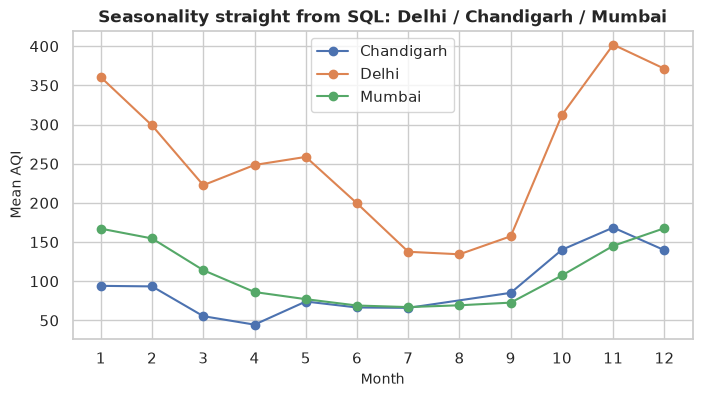

In [20]:
m = db.query(queries["q05_monthly_mean_core_cities"]["sql"], conn)
fig, ax = plt.subplots(figsize=(8, 4))
for city, g in m.groupby("city"):
    ax.plot(g["month"], g["mean_aqi"], marker="o", label=city)
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("Mean AQI"); ax.legend()
ax.set_title("Seasonality straight from SQL: Delhi / Chandigarh / Mumbai")
save_fig("01_sql_monthly_profile"); plt.show()

## 7 · Hand-written INSERT → UPDATE → DELETE, and ROLLBACK

A tiny, explicit demonstration of *modifying* the database (the pipeline above already did it at scale).

In [21]:
cid = conn.execute("SELECT city_id FROM dim_city WHERE city_name = 'Delhi'").fetchone()[0]
count = lambda: conn.execute("SELECT COUNT(*) FROM fact_aqi").fetchone()[0]
row = lambda: db.query("SELECT date, pm25, aqi, aqi_bucket FROM fact_aqi WHERE city_id = ? AND date = '2020-07-02'", conn, params=(cid,))
n0 = count(); print("rows before:", n0)

conn.execute("INSERT INTO fact_aqi (city_id, date, pm25, aqi) VALUES (?, '2020-07-02', 80.0, 150.0)", (cid,))   # CREATE
print("\nafter INSERT:"); display(row())

conn.execute("UPDATE fact_aqi SET aqi = 201, aqi_bucket = 'Poor' WHERE city_id = ? AND date = '2020-07-02'", (cid,))  # UPDATE
print("after UPDATE:"); display(row())

conn.execute("DELETE FROM fact_aqi WHERE city_id = ? AND date = '2020-07-02'", (cid,))                           # DELETE
conn.commit()
print("after DELETE:", len(row()), "rows found; table size back to", count(), "(was", n0, ")")
assert count() == n0

rows before: 28157

after INSERT:


,date,pm25,aqi,aqi_bucket
0,2020-07-02,80.0,150.0,None


after UPDATE:


,date,pm25,aqi,aqi_bucket
0,2020-07-02,80.0,201.0,Poor


after DELETE: 0 rows found; table size back to 28157 (was 28157 )


In [22]:
# ROLLBACK: a destructive statement that we undo – shows the transactional safety of a real database
print("non-null AQI values:", conn.execute("SELECT COUNT(aqi) FROM fact_aqi").fetchone()[0])
conn.execute("UPDATE fact_aqi SET aqi = NULL")                     # oops!
print("after the mistaken UPDATE :", conn.execute("SELECT COUNT(aqi) FROM fact_aqi").fetchone()[0])
conn.rollback()
print("after ROLLBACK             :", conn.execute("SELECT COUNT(aqi) FROM fact_aqi").fetchone()[0])

non-null AQI values: 24850
after the mistaken UPDATE : 0
after ROLLBACK             : 24850


## 8 · Integrity checks

In [23]:
checks = {}
raw_n = conn.execute("SELECT COUNT(*) FROM raw_city_day").fetchone()[0]
fact_n = conn.execute("SELECT COUNT(*) FROM fact_aqi").fetchone()[0]
checks["raw rows (29,531 loaded − 1,374 empty − 0 duplicates)"] = raw_n
checks["fact rows == raw rows"] = fact_n == raw_n
checks["duplicate (city_id, date) pairs"] = conn.execute("SELECT COUNT(*) FROM (SELECT 1 FROM fact_aqi GROUP BY city_id, date HAVING COUNT(*) > 1)").fetchone()[0]
checks["foreign-key violations"] = len(conn.execute("PRAGMA foreign_key_check").fetchall())
checks["AQI bucket inconsistent with AQI"] = conn.execute('''SELECT COUNT(*) FROM fact_aqi WHERE aqi IS NOT NULL AND aqi_bucket <>
    CASE WHEN aqi<=50 THEN 'Good' WHEN aqi<=100 THEN 'Satisfactory' WHEN aqi<=200 THEN 'Moderate'
         WHEN aqi<=300 THEN 'Poor' WHEN aqi<=400 THEN 'Very Poor' ELSE 'Severe' END''').fetchone()[0]
checks["negative concentrations"] = conn.execute("SELECT COUNT(*) FROM fact_aqi WHERE pm25<0 OR pm10<0 OR no2<0 OR so2<0 OR co<0 OR o3<0").fetchone()[0]
checks["cities in dim_city"] = conn.execute("SELECT COUNT(*) FROM dim_city").fetchone()[0]
pd.Series(checks, name="result").to_frame()

,result
"raw rows (29,531 loaded − 1,374 empty − 0 duplicates)",28157
fact rows == raw rows,True
"duplicate (city_id, date) pairs",0
foreign-key violations,0
AQI bucket inconsistent with AQI,0
negative concentrations,0
cities in dim_city,26


In [24]:
conn.close()
print(f"Database ready: {DB_PATH.relative_to(ROOT)}  ({DB_PATH.stat().st_size/1e6:.1f} MB)")

Database ready: db/aqi.db  (8.3 MB)


### Take-aways
* Raw CSV: 29,531 rows → **28,157 usable rows** in `fact_aqi` (1,374 completely empty rows deleted; 0 duplicates; 26 consistent city names).
* 5,913 rows had placeholder zeros that were converted to NULL; 547 rows flagged as outliers; **Ahmedabad flagged as suspect**.
* Every change is documented in `audit_log` – reproducible and auditable.

➡ Next: `02_cleaning_and_features.ipynb` reads from this database, imputes short gaps, engineers calendar / festival / lag features and writes `aqi_features` back to SQLite.